# Evaluación comparativa del clasificador de tráfico

Este cuaderno reproduce el conjunto de prueba estratificado 70/30 del entrenamiento y compara el **Booster XGBoost guardado** con las reglas deterministas de la API sobre exactamente las mismas filas. No optimiza ni entrena modelos. El análisis del solapamiento de combinaciones permite interpretar la capacidad de generalización del resultado. Ejecutar todas las celdas desde `src/main/python/model` con el entorno de `requirements.txt`.

**Fuentes:** `SDN-MPLS-ML-TechDemonstrator-Model-Training.ipynb` (limpieza, split y evaluación), `src/res/models/sdn_mpls_ml_model.json`, `sdn_mpls_ml_model_meta.json`, `sdn_mpls_ml_train_test_split_summary.json`, `src/main/python/api/app/model/sdn_mpls_ml_deterministic_predictor.py` y `src/main/python/api/configs/sdn_mpls_ml_traffic_class_deterministic_rules.json`. Las métricas finales históricas se usan solo como comprobación, nunca como entrada para las predicciones actuales.


## 1. Configuración y contrato de los artefactos

### 1.1 Importe de Librerias

In [1]:
from __future__ import annotations
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

### 1.2 Configuracion de rutas de modelos y reglas

In [2]:
def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'src/res/models/sdn_mpls_ml_model.json').is_file():
            return candidate
    raise FileNotFoundError('No se encontró la raíz del proyecto desde el directorio actual.')

In [3]:
#? La mayoria de estas rutas dependen directamente de la estructura del proyecto y de los artefactos generados por el entrenamiento.
ROOT = find_project_root(Path.cwd())
DATA_PATH = ROOT / 'src/res/data/processed/SDNFlow_Training_Sample_Dataset.csv'
MODEL_DIR = ROOT / 'src/res/models'
MODEL_PATH = MODEL_DIR / 'sdn_mpls_ml_model.json'
METADATA_PATH = MODEL_DIR / 'sdn_mpls_ml_model_meta.json'
SPLIT_PATH = MODEL_DIR / 'sdn_mpls_ml_train_test_split_summary.json'
HISTORICAL_METRICS_PATH = MODEL_DIR / 'sdn_mpls_ml_final_metrics.json'
RULES_PATH = ROOT / 'src/main/python/api/configs/sdn_mpls_ml_traffic_class_deterministic_rules.json'
FIGURES_DIR = ROOT / 'src/res/figures/model-comparison'
TABLES_DIR = FIGURES_DIR / 'tables'
SAVE_OUTPUTS = True
TIMING_SAMPLE_SIZE = 1000
TIMING_REPEATS = 3

metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
split_summary = json.loads(SPLIT_PATH.read_text(encoding='utf-8'))
historical_metrics = json.loads(HISTORICAL_METRICS_PATH.read_text(encoding='utf-8'))
feature_columns = metadata['feature_order']
target_column = metadata['target_name']
class_to_id = metadata['class_to_id']
classes = [metadata['id_to_class'][str(i)] for i in range(len(class_to_id))]
class_ids = list(range(len(classes)))
assert feature_columns == ['eth_type', 'ip_proto', 'src_port', 'dst_port']
assert class_to_id == {name: i for i, name in enumerate(classes)}
assert feature_columns == split_summary['feature_columns']
assert class_to_id == split_summary['class_to_id']
assert split_summary['target_column'] == target_column

rules = json.loads(RULES_PATH.read_text(encoding='utf-8'))
assert rules['schema_version'] == '1.0'
assert set(rules['destination_port_class_map'].values()) <= set(classes)
assert set(rules['source_port_class_map'].values()) <= set(classes)
assert rules['streaming_class_name'] == 'STREAMING'


### 1.3 Función de clasificación determinista
Esta funcion se toma directamente de la API y se adapta para que funcione con un diccionario de features en lugar de un objeto de paquete. Se mantiene la prioridad ICMP > puerto destino > puerto origen > STREAMING, que coincide con la API.

In [4]:
def classify_with_production_rules(packet: dict[str, int]) -> int:
    # Transcripción de DeterministicClassifier._classify: ICMP, destino, origen, fallback.
    if packet['ip_proto'] == rules['icmp_ip_protocol']:
        name = 'ICMP'
    elif str(packet['dst_port']) in rules['destination_port_class_map']:
        name = rules['destination_port_class_map'][str(packet['dst_port'])]
    elif str(packet['src_port']) in rules['source_port_class_map']:
        name = rules['source_port_class_map'][str(packet['src_port'])]
    else:
        # Ambos caminos de well_known_port_threshold en producción devuelven STREAMING.
        name = rules['streaming_class_name']
    return class_to_id[name]


### 1.4 Carga del modelo XGBoost guardado
En este bloque se carga el modelo preentrenado XGBoost usado para la clasificacion en la API en produccion

In [5]:
booster = xgb.Booster()
booster.load_model(MODEL_PATH)
assert booster.num_features() == len(feature_columns)
sns.set_theme(style='white', font_scale=1)
print(f'Modelo: {MODEL_PATH} | clases: {classes}')
print(f'Reglas: {RULES_PATH} | split: {split_summary["random_state"]}, {split_summary["test_size"]:.0%}')

Modelo: /Users/santiagoarellano/Documents/Projects/SDN-MPLS-ML Technology Demostrator/src/res/models/sdn_mpls_ml_model.json | clases: ['DNS', 'FTP', 'HTTP', 'ICMP', 'NTP', 'SSH', 'STREAMING']
Reglas: /Users/santiagoarellano/Documents/Projects/SDN-MPLS-ML Technology Demostrator/src/main/python/api/configs/sdn_mpls_ml_traffic_class_deterministic_rules.json | split: 42, 30%


### 1.5 Configuracion de funciones de visualizacion y exportacion

In [6]:
def export_table(frame: pd.DataFrame, name: str, keep_index: bool = False) -> None:
    if SAVE_OUTPUTS:
        TABLES_DIR.mkdir(parents=True, exist_ok=True)
        frame.to_csv(TABLES_DIR / f'{name}.csv', index=keep_index, encoding='utf-8')

def finalize_figure(fig, name: str) -> None:
    # El diseño reserva una banda fija sobre el gráfico para título y subtítulo.
    if SAVE_OUTPUTS:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_DIR / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def styled_heading(fig, ax, title: str, subtitle: str) -> None:
    fig.tight_layout(rect=(0, 0, 1, 0.84))
    left = ax.get_position().x0
    fig.suptitle(title, x=left, y=1.00, ha='left', fontsize=14, fontweight='bold')
    fig.text(left, 0.95, subtitle, ha='left', va='top', fontsize=12,
             fontstyle='italic', color='#64748b')

def clean_axes(ax) -> None:
    ax.grid(False)
    ax.tick_params(axis='both', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=10)

## 2. Recuperación del conjunto de prueba original

### 2.1 Carga de los datos y evaluacion de features requeridas

In [7]:
raw = pd.read_csv(DATA_PATH, sep=',', encoding='utf-8')
required = feature_columns + [target_column]
missing = set(required) - set(raw.columns)
if missing:
    raise KeyError(f'Columnas ausentes: {sorted(missing)}')

### 2.2 Limpieza de los datos y correccion de tipos

In [8]:
df = raw[required].copy()
df[target_column] = df[target_column].astype('string').str.strip().str.upper()
df[target_column] = df[target_column].mask(df[target_column].isin({'', 'NULL', 'NONE', 'NAN', 'NA', 'N/A', '?'}), pd.NA)
for feature in feature_columns:
    df[feature] = pd.to_numeric(df[feature], errors='coerce')
df = df.loc[~df[required].isna().any(axis=1)].copy()

### 2.3 Evaluacion de los limites necesarios de los datos para la validacion
Esta seccion emula las verificaciones de limites logicos de las variables registradas en el mismo estilo que el notebook
 de entrenamiento.

In [9]:
# Misma selección, orden de limpieza y split que las secciones 3 y 4 del notebook de entrenamiento.

bounds = {'eth_type': (0, 65535), 'ip_proto': (0, 255), 'src_port': (0, 65535), 'dst_port': (0, 65535)}
invalid_range = pd.Series(False, index=df.index)
for feature, (lower, upper) in bounds.items():
    invalid_range |= df[feature].lt(lower) | df[feature].gt(upper)
df = df.loc[~invalid_range].copy()
non_integral = pd.Series(False, index=df.index)
for feature in feature_columns:
    non_integral |= ~np.isclose(df[feature] % 1, 0)
df = df.loc[~non_integral].copy()
for feature in feature_columns:
    df[feature] = df[feature].astype('Int64')
df = df.loc[df[target_column].isin(classes)].reset_index(drop=True)

### 2.4 Split estratificado de entrenamiento y prueba

In [10]:
X = df[feature_columns].to_numpy(dtype=np.float32)
y = df[target_column].map(class_to_id).to_numpy(dtype=np.int64)
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=split_summary['test_size'],
                                       random_state=split_summary['random_state'], stratify=y)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
assert len(train_idx) == split_summary['train_rows']
assert len(test_idx) == split_summary['test_rows']
for label, selected, key in [('train', train_idx, 'train_distribution'), ('test', test_idx, 'test_distribution')]:
    actual = df.iloc[selected][target_column].value_counts().to_dict()
    expected = {row['class_name']: row['count'] for row in split_summary[key]}
    assert actual == expected, f'La distribución {label} difiere del artefacto de entrenamiento.'
print(f'Filas limpias: {len(df):,}; entrenamiento: {len(train_idx):,}; prueba: {len(test_idx):,}')


Filas limpias: 221,564; entrenamiento: 155,094; prueba: 66,470


In [11]:
df.iloc[test_idx][target_column].value_counts().reindex(classes, fill_value=0).rename('soporte_prueba').to_frame()

,soporte_prueba
Category,
DNS,16065
FTP,27
HTTP,49493
ICMP,92
NTP,7
SSH,340
STREAMING,446


In [50]:
df.iloc[train_idx][target_column].value_counts().reindex(classes, fill_value=0).rename('soporte_entrenamiento').to_frame()

,soporte_entrenamiento
Category,
DNS,37486
FTP,64
HTTP,115481
ICMP,213
NTP,16
SSH,793
STREAMING,1041


## 3. Inferencia sobre las mismas filas

### 3.1 Definición de funciones de predicción
Esta seccion define las funciones de predicción para el modelo XGBoost y para las reglas deterministas, asegurando que ambas produzcan resultados comparables sobre el mismo conjunto de prueba.

In [12]:
def predict_xgboost(matrix: np.ndarray) -> np.ndarray:
    probabilities = np.asarray(booster.predict(xgb.DMatrix(matrix)), dtype=np.float32)
    assert probabilities.shape == (len(matrix), len(classes))
    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-3)
    return probabilities

def predict_baseline(matrix: np.ndarray) -> np.ndarray:
    # La prioridad ICMP > puerto destino > puerto origen > STREAMING coincide con la API.
    return np.fromiter((classify_with_production_rules(dict(zip(feature_columns, map(int, row))))
                        for row in matrix), dtype=np.int64, count=len(matrix))

probabilities = predict_xgboost(X_test)
y_xgb = probabilities.argmax(axis=1)
y_rules = predict_baseline(X_test)
assert len(y_xgb) == len(y_rules) == len(y_test)
print('Predicciones generadas sobre el mismo test set. Desacuerdos en la clasificacion:', int(np.count_nonzero(y_xgb != y_rules)))


Predicciones generadas sobre el mismo test set. Desacuerdos en la clasificacion: 392


### 3.2 Comparacion de las predicciones y visualizacion de los desacuerdos.
Esta seccion permite evidenciar directamente los desacuerdos y las entradas que los causaron.

In [13]:
disagreement_mask = y_xgb != y_rules

review_df = (
    df.iloc[test_idx[disagreement_mask]]
      .copy()
      .assign(
          y_true=y_test[disagreement_mask],
          pred_rules=y_rules[disagreement_mask],
          pred_xgb=y_xgb[disagreement_mask],
          rules_correct=(y_rules[disagreement_mask] == y_test[disagreement_mask]),
          xgb_correct=(y_xgb[disagreement_mask] == y_test[disagreement_mask]),
          xgb_confidence=probabilities[disagreement_mask].max(axis=1)
      )
)
review_df

,eth_type,ip_proto,src_port,dst_port,Category,y_true,pred_rules,pred_xgb,rules_correct,xgb_correct,xgb_confidence
55740,2048,6,8080,60288,STREAMING,6,2,6,False,True,0.999869
70767,2048,6,8080,43504,STREAMING,6,2,6,False,True,0.999854
109646,2048,6,48018,8080,STREAMING,6,2,6,False,True,0.999951
197331,2048,6,48112,8080,STREAMING,6,2,6,False,True,0.999954
38,2048,6,42448,8080,STREAMING,6,2,6,False,True,0.999830
...,...,...,...,...,...,...,...,...,...,...,...
135757,2048,6,8080,44640,STREAMING,6,2,6,False,True,0.999862
124276,2048,6,8080,44416,STREAMING,6,2,6,False,True,0.999854
159365,2048,6,8080,58492,STREAMING,6,2,6,False,True,0.999869
158649,2048,6,36904,8080,STREAMING,6,2,6,False,True,0.999893


### 3.3 Visualizacion de la distribucion de clases en los registros de desacuerdos

In [14]:
disagreement_dist = (
    review_df["Category"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percentage")
    .reset_index()
)

disagreement_dist.columns = ["Category", "percentage"]
disagreement_dist

,Category,percentage
0,STREAMING,82.653061
1,HTTP,16.071429
2,NTP,1.27551


/var/folders/3c/vp72r8cx1kx1z2gvmfkybjqc0000gn/T/ipykernel_12503/2490323352.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=10)


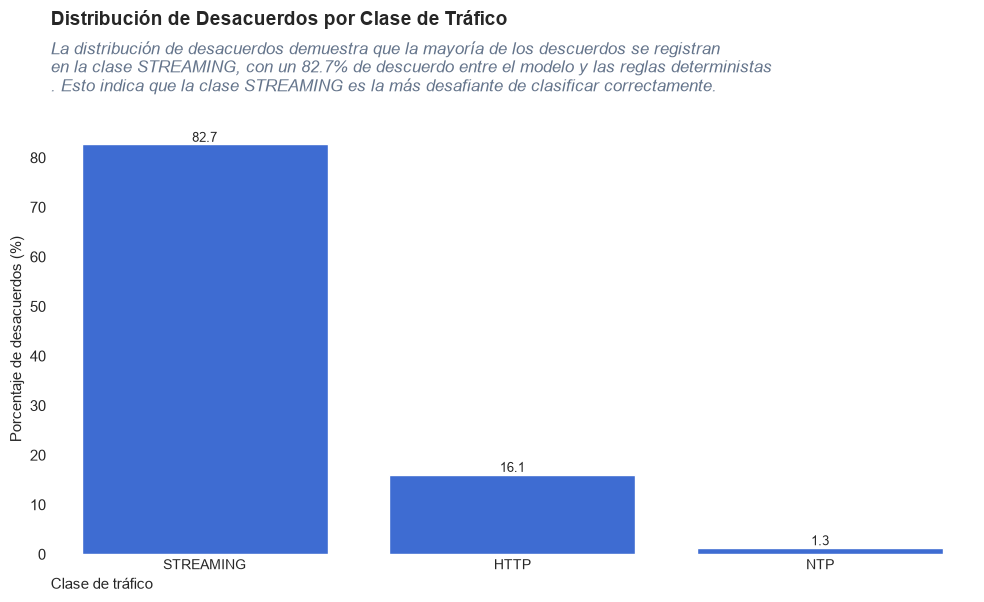

In [15]:

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=disagreement_dist,
    x="Category",
    y="percentage",
    color="#2563eb",
    ax=ax
)

ax.set_ylabel("Porcentaje de desacuerdos (%)", fontsize=11)
ax.set_xlabel("Clase de tráfico", fontsize=11, ha='left', x=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=9)
clean_axes(ax)
styled_heading(
    fig,
    ax,
    "Distribución de Desacuerdos por Clase de Tráfico",
    "La distribución de desacuerdos demuestra que la mayoría de los descuerdos se registran\nen la clase STREAMING, "
    "con un 82.7% de descuerdo entre el modelo y las reglas deterministas\n. Esto indica que la clase STREAMING es la "
    "más desafiante de clasificar correctamente."
)
finalize_figure(fig, "03_desacuerdos_por_clase")

### 3.4  Visualizacion de la Matriz de Confusión de los desacuerdos entre el modelo entrenado y las reglas deterministas

In [16]:
EXPECTED_CLASSES = [
    "DNS",
    "FTP",
    "HTTP",
    "ICMP",
    "NTP",
    "SSH",
    "STREAMING",
]

CLASS_TO_ID = {
    class_name: class_id
    for class_id, class_name in enumerate(EXPECTED_CLASSES)
}

id_to_class = {v: k for k, v in CLASS_TO_ID.items()}

review_df["true_class"] = review_df["y_true"].map(id_to_class)
review_df["rules_class"] = review_df["pred_rules"].map(id_to_class)
review_df["xgb_class"] = review_df["pred_xgb"].map(id_to_class)

In [17]:
cross = pd.crosstab(
    review_df["rules_class"],
    review_df["xgb_class"]
)

cross

xgb_class,HTTP,STREAMING
rules_class,,
HTTP,0,324
NTP,66,0
STREAMING,2,0


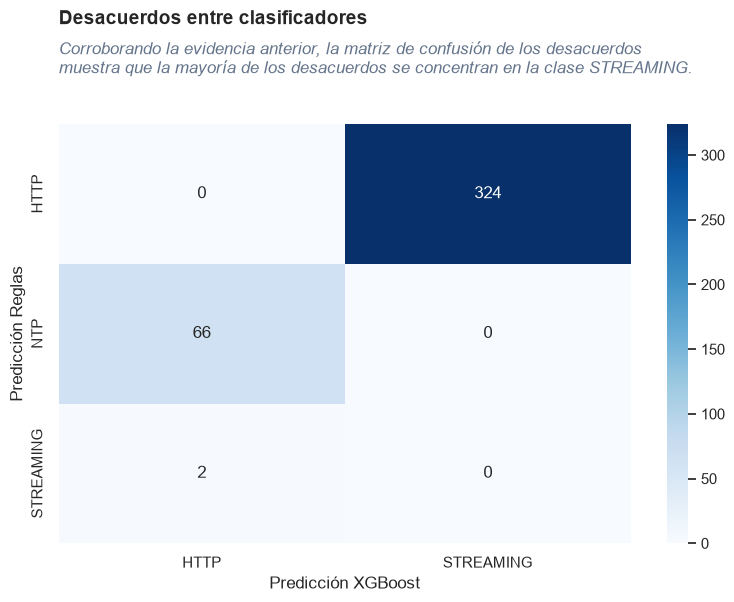

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cross,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax
)

ax.set_xlabel("Predicción XGBoost")
ax.set_ylabel("Predicción Reglas")

styled_heading(
    fig,
    ax,
    "Desacuerdos entre clasificadores",
    "Corroborando la evidencia anterior, la matriz de confusión de los desacuerdos\nmuestra que la mayoría de los "
    "desacuerdos se concentran en la clase STREAMING. "
)

finalize_figure(fig, "heatmap_desacuerdos")

### 3.5 Visualizacion de los casos en los casos de acierto de cada modelo

In [19]:
review_df["winner"] = np.select(
    [
        (~review_df["rules_correct"]) & ( review_df["xgb_correct"]),
        ( review_df["rules_correct"]) & (~review_df["xgb_correct"]),
    ],
    [
        "XGBoost",
        "Reglas"
    ],
    default="Ambos incorrectos"
)

winner_counts = (
    review_df["winner"]
    .value_counts()
    .rename_axis("ganador")
    .reset_index(name="casos")
)

export_table(
    winner_counts,
    "ganador_desacuerdos"
)

winner_counts

,ganador,casos
0,XGBoost,387
1,Reglas,5


/var/folders/3c/vp72r8cx1kx1z2gvmfkybjqc0000gn/T/ipykernel_12503/1070210682.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/3c/vp72r8cx1kx1z2gvmfkybjqc0000gn/T/ipykernel_12503/1070210682.py:3: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(
/var/folders/3c/vp72r8cx1kx1z2gvmfkybjqc0000gn/T/ipykernel_12503/2490323352.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=10)


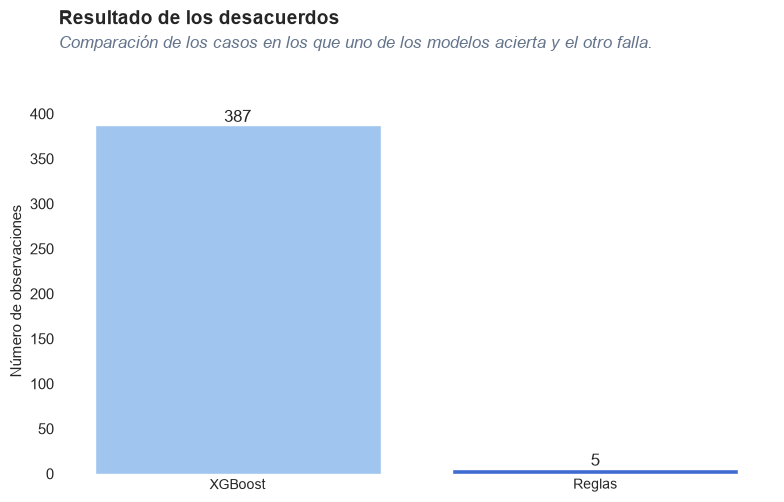

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=winner_counts,
    x="ganador",
    y="casos",
    palette=["#93c5fd", "#2563eb", "#94a3b8"],
    ax=ax
)

ax.set_ylabel("Número de observaciones", fontsize=11)
ax.set_xlabel("", fontsize=11)

for container in ax.containers:
    ax.bar_label(container, fmt='%d')

clean_axes(ax)

styled_heading(
    fig,
    ax,
    "Resultado de los desacuerdos",
    "Comparación de los casos en los que uno de los modelos acierta y el otro falla."
)

finalize_figure(fig, "05_ganador_desacuerdos")

## 4. Accuracy, Macro-F1 y métricas por clase

### 4.1 Cálculo de métricas globales y por clase

In [21]:
predictions = {'Modelo XGBoost Entrenado': y_xgb, 'Reglas deterministas': y_rules}
global_rows = []
class_rows = []
for method, predicted in predictions.items():
    report = classification_report(y_test, predicted, labels=class_ids, target_names=classes,
                                   output_dict=True, zero_division=0)
    global_rows.append({'método': method, 'accuracy': accuracy_score(y_test, predicted),
                        'macro_precision': report['macro avg']['precision'],
                        'macro_recall': report['macro avg']['recall'],
                        'macro_f1': f1_score(y_test, predicted, labels=class_ids,
                                             average='macro', zero_division=0),
                        'weighted_f1': report['weighted avg']['f1-score']})
    for name in classes:
        class_rows.append({'método': method, 'clase': name, 'precision': report[name]['precision'],
                           'recall': report[name]['recall'], 'f1': report[name]['f1-score'],
                           'soporte': int(report[name]['support'])})

In [22]:
global_metrics = pd.DataFrame(global_rows)
global_metrics

,método,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Modelo XGBoost Entrenado,0.999654,0.872364,0.897907,0.879647,0.999723
1,Reglas deterministas,0.993907,0.863582,0.895987,0.796620,0.993024


In [23]:
class_metrics = pd.DataFrame(class_rows)
class_metrics

,método,clase,precision,recall,f1,soporte
0,Modelo XGBoost Entrenado,DNS,1.000000,1.000000,1.000000,16065
1,Modelo XGBoost Entrenado,FTP,1.000000,1.000000,1.000000,27
2,Modelo XGBoost Entrenado,HTTP,0.999899,0.999636,0.999768,49493
3,Modelo XGBoost Entrenado,ICMP,1.000000,1.000000,1.000000,92
4,Modelo XGBoost Entrenado,NTP,0.111111,0.285714,0.160000,7
5,Modelo XGBoost Entrenado,SSH,1.000000,1.000000,1.000000,340
6,Modelo XGBoost Entrenado,STREAMING,0.995536,1.000000,0.997763,446
7,Reglas deterministas,DNS,1.000000,1.000000,1.000000,16065
8,Reglas deterministas,FTP,1.000000,1.000000,1.000000,27
9,Reglas deterministas,HTTP,0.993486,0.998363,0.995919,49493


### Exporacion de las tablas de metricas para registro de resultados y comparacion con el artefacto historico

In [24]:
export_table(global_metrics, '01_metricas_globales')
export_table(class_metrics, '02_metricas_por_clase')
print('Macro-F1 XGBoost histórico:', historical_metrics['final_test_metrics']['macro_f1'])
assert np.isclose(global_metrics.loc[0, 'macro_f1'], historical_metrics['final_test_metrics']['macro_f1']), 'La métrica XGBoost no reproduce el artefacto histórico.'


Macro-F1 XGBoost histórico: 0.8796472109891694


### 4.1 Representacion visual del rendimiento global del modelo entrenado y las reglas deterministas bajo el conjunto de prueba
 El siguiente grafico muestra la comparativa directa de las metricas de Accuracy, Macro Precision, Macro Recall y
 Macro-F1 entre el modelo entrenado de XGBoost y las reglas deterministas. Se puede observar que el modelo entrenado
 supera a las reglas deterministas en todas las métricas, lo que indica un mejor rendimiento en la clasificación del
 tráfico de red. Con especial relevancia al hablar del Macro-F1, que combina la precision y el recall teniendo en cuenta
  todas las clases.

### 4.2 Representación visual del rendimiento global del modelo entrenado y las reglas deterministas bajo el conjunto de prueba

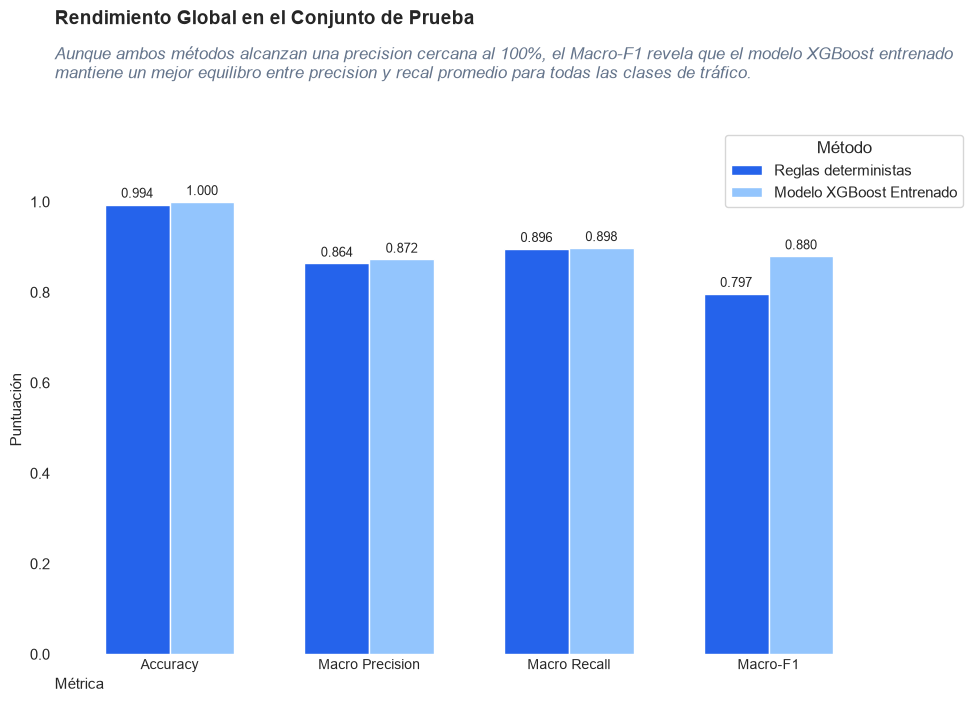

In [25]:
# Se fijan los colores por nombre de método, independientemente del orden de las columnas.
METHOD_COLORS = {'Reglas deterministas': '#2563eb', 'Modelo XGBoost Entrenado': '#93c5fd'}
METHOD_ORDER = ['Reglas deterministas', 'Modelo XGBoost Entrenado']

plot_metrics = (global_metrics.set_index('método')[['accuracy', 'macro_precision',
                                                    'macro_recall','macro_f1']]
                .T.reindex(columns=METHOD_ORDER))
fig, ax = plt.subplots(figsize=(10, 7))
plot_metrics.plot.bar(ax=ax, color=[METHOD_COLORS[m] for m in plot_metrics.columns], width=0.65)
ax.set_ylim(0, 1.08)
ax.set_xticklabels(['Accuracy','Macro Precision','Macro Recall', 'Macro-F1'], rotation=0, fontsize=10)
ax.set_ylabel('Puntuación', fontsize=11)
ax.set_xlabel('Métrica', fontsize=11, ha='left', x=0)
ax.legend(title='Método', frameon=True, bbox_to_anchor=(0.8, 0.9))
clean_axes(ax)
styled_heading(fig, ax, 'Rendimiento Global en el Conjunto de Prueba',
               'Aunque ambos métodos alcanzan una precision cercana al 100%, el Macro-F1 revela que el modelo '
               'XGBoost entrenado\nmantiene un mejor equilibro entre precision y recal promedio para todas las clases'
               ' de tráfico.')
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.3f',      # three decimals
        fontsize=9,
        padding=3
    )
finalize_figure(fig, '01_metricas_globales')


### 4.3 Representación visual del F1-Score por clase de tráfico y método de clasificación

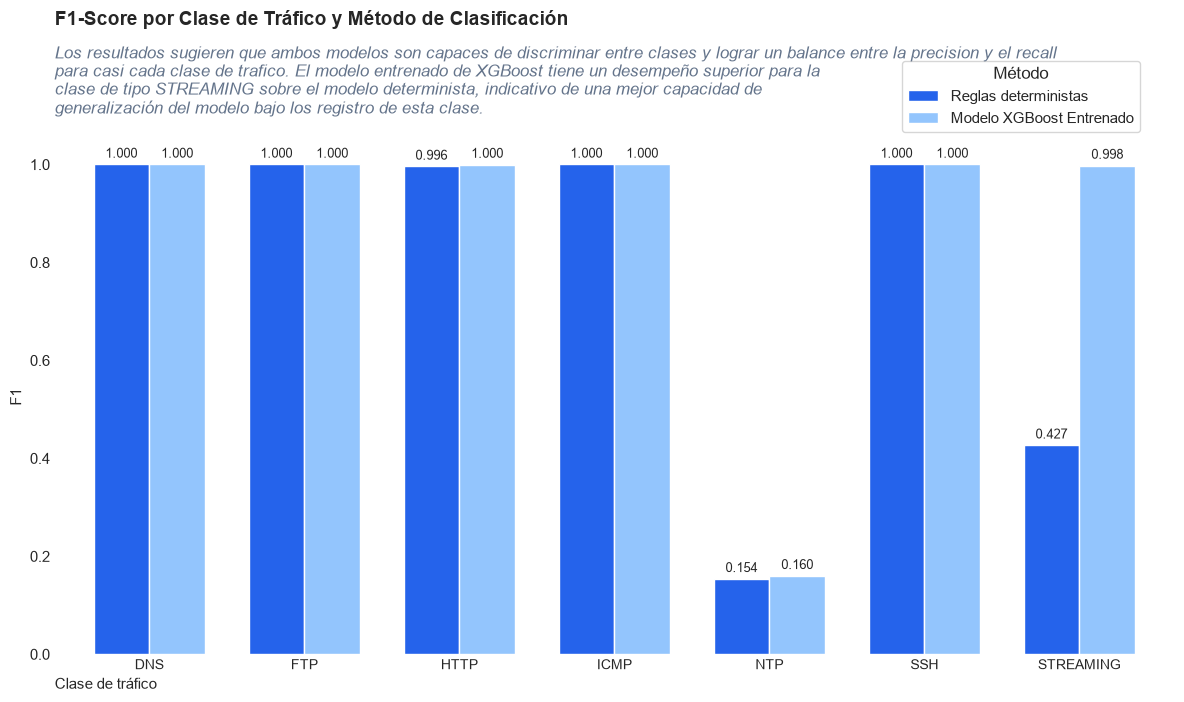

In [26]:
f1_plot = (class_metrics.pivot(index='clase', columns='método', values='f1')
           .reindex(index=classes, columns=METHOD_ORDER))
fig, ax = plt.subplots(figsize=(12, 7))
f1_plot.plot.bar(ax=ax, color=[METHOD_COLORS[m] for m in f1_plot.columns], width=0.72)
ax.set_ylabel('F1', fontsize=11)
ax.set_xlabel('Clase de tráfico', fontsize=11, ha='left', x=0)
legend_for_configuration = ax.legend(title='Método', frameon=True, bbox_to_anchor=(0.75, 1))
legend_for_configuration.set_in_layout(False)
clean_axes(ax)
styled_heading(fig, ax, 'F1-Score por Clase de Tráfico y Método de Clasificación',
               'Los resultados sugieren que ambos modelos son capaces de discriminar entre clases y lograr un '
               'balance entre la precision y el recall\npara casi cada clase de trafico. El modelo entrenado de '
               'XGBoost tiene un desempeño superior para la\nclase de tipo STREAMING sobre el modelo determinista, '
               'indicativo de una mejor capacidad de\ngeneralización del modelo bajo los registro de esta clase.')
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.3f',      # three decimals
        fontsize=9,
        padding=3
    )
finalize_figure(fig, '02_f1_por_clase')

## 5. Matrices de confusión

### 5.1 Matriz de confusion absoluta para el modelo entrenado de XGBoost

In [27]:
# Tabla: matriz de confusión absoluta de XGBoost.
cm_xgboost_absoluta = pd.DataFrame(
    confusion_matrix(y_test, predictions['Modelo XGBoost Entrenado'], labels=class_ids, normalize=None),
    index=classes,
    columns=classes,
)
export_table(cm_xgboost_absoluta.rename_axis('clase_real'), '03_matriz_xgboost_absoluta', keep_index=True)

In [28]:
cm_xgboost_absoluta

,DNS,FTP,HTTP,ICMP,NTP,SSH,STREAMING
DNS,16065,0,0,0,0,0,0
FTP,0,27,0,0,0,0,0
HTTP,0,0,49475,0,16,0,2
ICMP,0,0,0,92,0,0,0
NTP,0,0,5,0,2,0,0
SSH,0,0,0,0,0,340,0
STREAMING,0,0,0,0,0,0,446


### 5.2 Visualiacion de la matriz de confusion del modelo entrenado de XGBoost

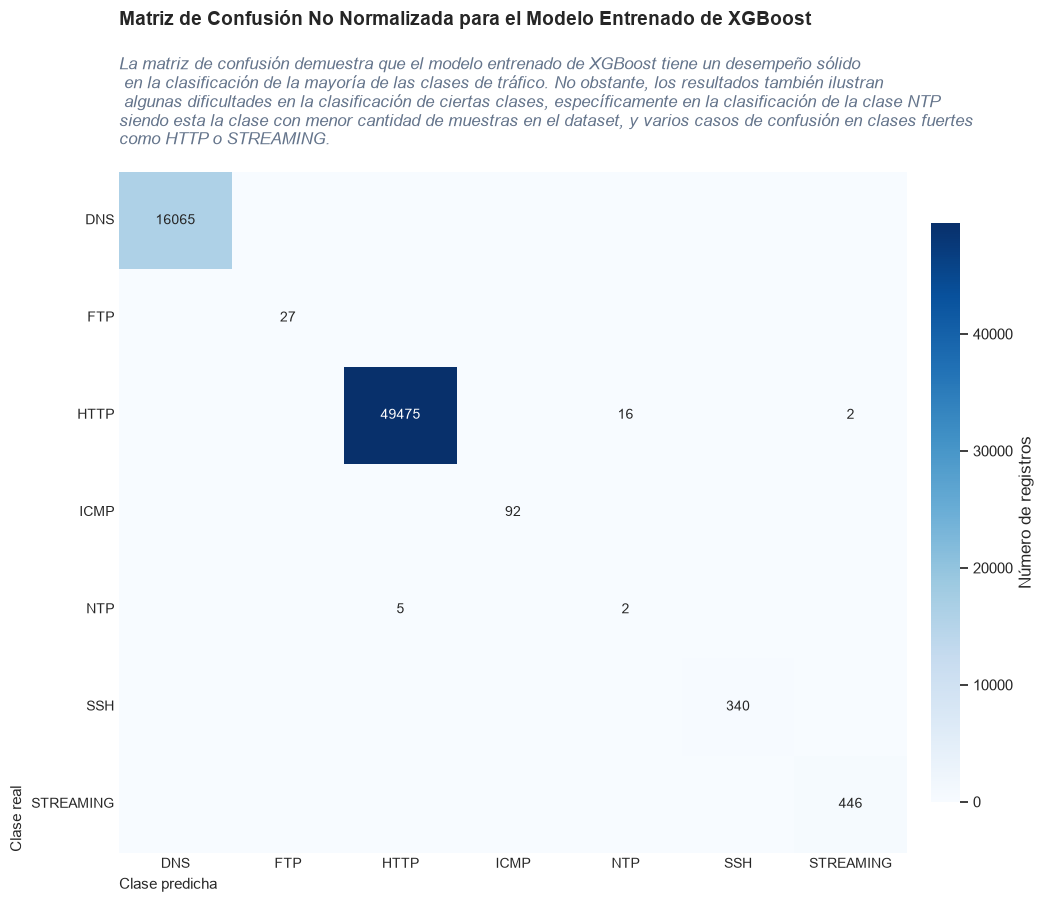

In [29]:
annotations = cm_xgboost_absoluta.map(lambda value: f'{int(value)}' if value else '')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_xgboost_absoluta, annot=annotations, fmt='', cmap='Blues', vmin=0,
    vmax=None, linewidths=0,
    annot_kws={'fontsize': 10},
    cbar_kws={'label': 'Número de registros',
               'shrink': 0.85, 'pad': 0.025}, ax=ax,
)
clean_axes(ax)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)
ax.set_xlabel('Clase predicha', fontsize=11, ha='left', x=0, labelpad=5)
ax.set_ylabel('Clase real', fontsize=11, va='bottom', y=0.05, labelpad=5)
styled_heading(fig, ax, 'Matriz de Confusión No Normalizada para el Modelo Entrenado de XGBoost',
               'La matriz de confusión demuestra que el modelo entrenado de XGBoost tiene un desempeño sólido\n'
               ' en la clasificación de la mayoría de las clases de tráfico. No obstante, los resultados también ilustran\n'
               ' algunas dificultades en la clasificación de ciertas clases, específicamente en la clasificación de la clase NTP\n'
               'siendo esta la clase con menor cantidad de muestras en el dataset, y varios casos de confusión en clases fuertes\n'
               'como HTTP o STREAMING.')
finalize_figure(fig, '03_matriz_xgboost_absoluta')

### 5.3 Matriz de confusión normalizada para el modelo entrenado de XGBoost

In [30]:
cm_xgboost_normalizada = pd.DataFrame(
    confusion_matrix(y_test, predictions['Modelo XGBoost Entrenado'], labels=class_ids, normalize='true'),
    index=classes,
    columns=classes,
)
export_table(cm_xgboost_normalizada.rename_axis('clase_real'), '03_matriz_xgboost_normalizada', keep_index=True)

In [31]:
cm_xgboost_normalizada

,DNS,FTP,HTTP,ICMP,NTP,SSH,STREAMING
DNS,1.0,0.0,0.000000,0.0,0.000000,0.0,0.00000
FTP,0.0,1.0,0.000000,0.0,0.000000,0.0,0.00000
HTTP,0.0,0.0,0.999636,0.0,0.000323,0.0,0.00004
ICMP,0.0,0.0,0.000000,1.0,0.000000,0.0,0.00000
NTP,0.0,0.0,0.714286,0.0,0.285714,0.0,0.00000
SSH,0.0,0.0,0.000000,0.0,0.000000,1.0,0.00000
STREAMING,0.0,0.0,0.000000,0.0,0.000000,0.0,1.00000


### 5.4 Visualización de la matriz de confusión normalizada del modelo entrenado de XGBoost

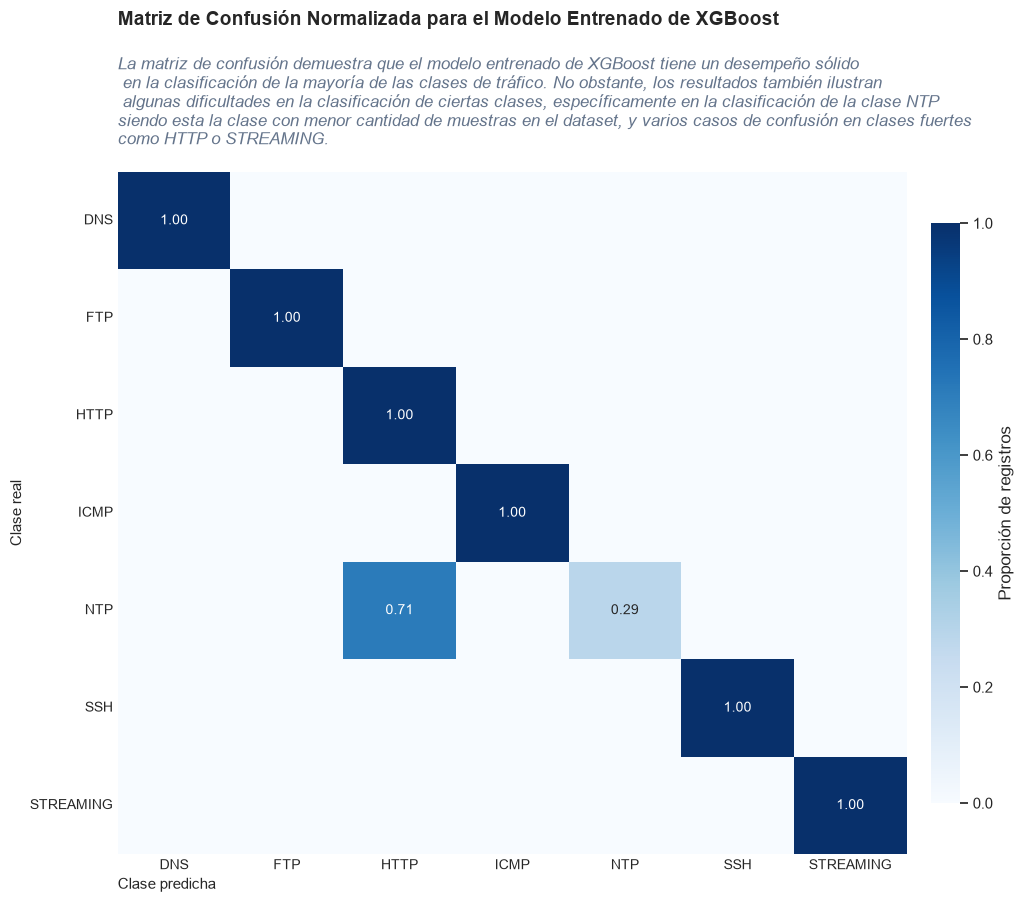

In [32]:
annotations = cm_xgboost_normalizada.map(lambda value: f'{value:.2f}' if value >= 0.005 else '')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_xgboost_normalizada, annot=annotations, fmt='', cmap='Blues', vmin=0,
    vmax=1, linewidths=0,
    annot_kws={'fontsize': 10},
    cbar_kws={'label': 'Proporción de registros',
               'shrink': 0.85, 'pad': 0.025}, ax=ax,
)
clean_axes(ax)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)
ax.set_xlabel('Clase predicha', fontsize=11, ha='left', x=0)
ax.set_ylabel('Clase real', fontsize=11)
styled_heading(fig, ax, 'Matriz de Confusión Normalizada para el Modelo Entrenado de XGBoost',
               'La matriz de confusión demuestra que el modelo entrenado de XGBoost tiene un desempeño sólido\n'
               ' en la clasificación de la mayoría de las clases de tráfico. No obstante, los resultados también ilustran\n'
               ' algunas dificultades en la clasificación de ciertas clases, específicamente en la clasificación de la clase NTP\n'
               'siendo esta la clase con menor cantidad de muestras en el dataset, y varios casos de confusión en clases fuertes\n'
               'como HTTP o STREAMING.')
finalize_figure(fig, '03_matriz_xgboost_normalizada')

### 5.5 Matriz de confusión absoluta para las reglas deterministas

In [33]:
cm_reglas_absoluta = pd.DataFrame(
    confusion_matrix(y_test, predictions['Reglas deterministas'], labels=class_ids, normalize=None),
    index=classes,
    columns=classes,
)
export_table(cm_reglas_absoluta.rename_axis('clase_real'), '03_matriz_reglas_absoluta', keep_index=True)

In [34]:
cm_reglas_absoluta

,DNS,FTP,HTTP,ICMP,NTP,SSH,STREAMING
DNS,16065,0,0,0,0,0,0
FTP,0,27,0,0,0,0,0
HTTP,0,0,49412,0,77,0,4
ICMP,0,0,0,92,0,0,0
NTP,0,0,0,0,7,0,0
SSH,0,0,0,0,0,340,0
STREAMING,0,0,324,0,0,0,122


### 5.6 Visualización de la matriz de confusión absoluta de las reglas deterministas

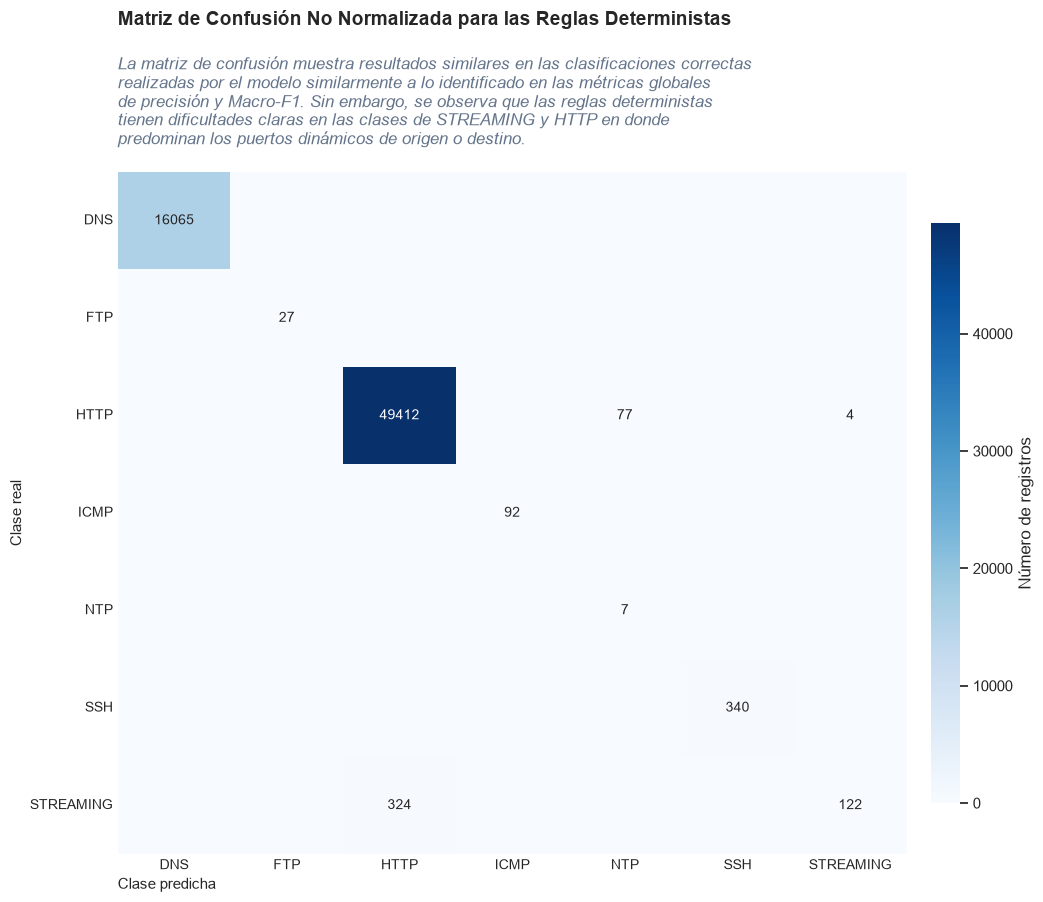

In [35]:
annotations = cm_reglas_absoluta.map(lambda value: f'{int(value)}' if value else '')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_reglas_absoluta, annot=annotations, fmt='', cmap='Blues', vmin=0,
    vmax=None, linewidths=0,
    annot_kws={'fontsize': 10},
    cbar_kws={'label': 'Número de registros',
               'shrink': 0.85, 'pad': 0.025}, ax=ax,
)
clean_axes(ax)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)
ax.set_xlabel('Clase predicha', fontsize=11, ha='left', x=0)
ax.set_ylabel('Clase real', fontsize=11)
styled_heading(fig, ax, 'Matriz de Confusión No Normalizada para las Reglas Deterministas',
               'La matriz de confusión muestra resultados similares en las clasificaciones correctas\n'
               'realizadas por el modelo similarmente a lo identificado en las métricas globales\n'
               'de precisión y Macro-F1. Sin embargo, se observa que las reglas deterministas\n'
               'tienen dificultades claras en las clases de STREAMING y HTTP en donde\n'
               'predominan los puertos dinámicos de origen o destino.')
finalize_figure(fig, '03_matriz_reglas_absoluta')

### 5.7 Matriz de confusion normalizada para las reglas deterministas

In [36]:
cm_reglas_normalizada = pd.DataFrame(
    confusion_matrix(y_test, predictions['Reglas deterministas'], labels=class_ids, normalize='true'),
    index=classes,
    columns=classes,
)
export_table(cm_reglas_normalizada.rename_axis('clase_real'), '03_matriz_reglas_normalizada', keep_index=True)

In [37]:
cm_reglas_normalizada

,DNS,FTP,HTTP,ICMP,NTP,SSH,STREAMING
DNS,1.0,0.0,0.000000,0.0,0.000000,0.0,0.000000
FTP,0.0,1.0,0.000000,0.0,0.000000,0.0,0.000000
HTTP,0.0,0.0,0.998363,0.0,0.001556,0.0,0.000081
ICMP,0.0,0.0,0.000000,1.0,0.000000,0.0,0.000000
NTP,0.0,0.0,0.000000,0.0,1.000000,0.0,0.000000
SSH,0.0,0.0,0.000000,0.0,0.000000,1.0,0.000000
STREAMING,0.0,0.0,0.726457,0.0,0.000000,0.0,0.273543


### 5.8 Visualización de la matriz de confusión normalizada de las reglas deterministas

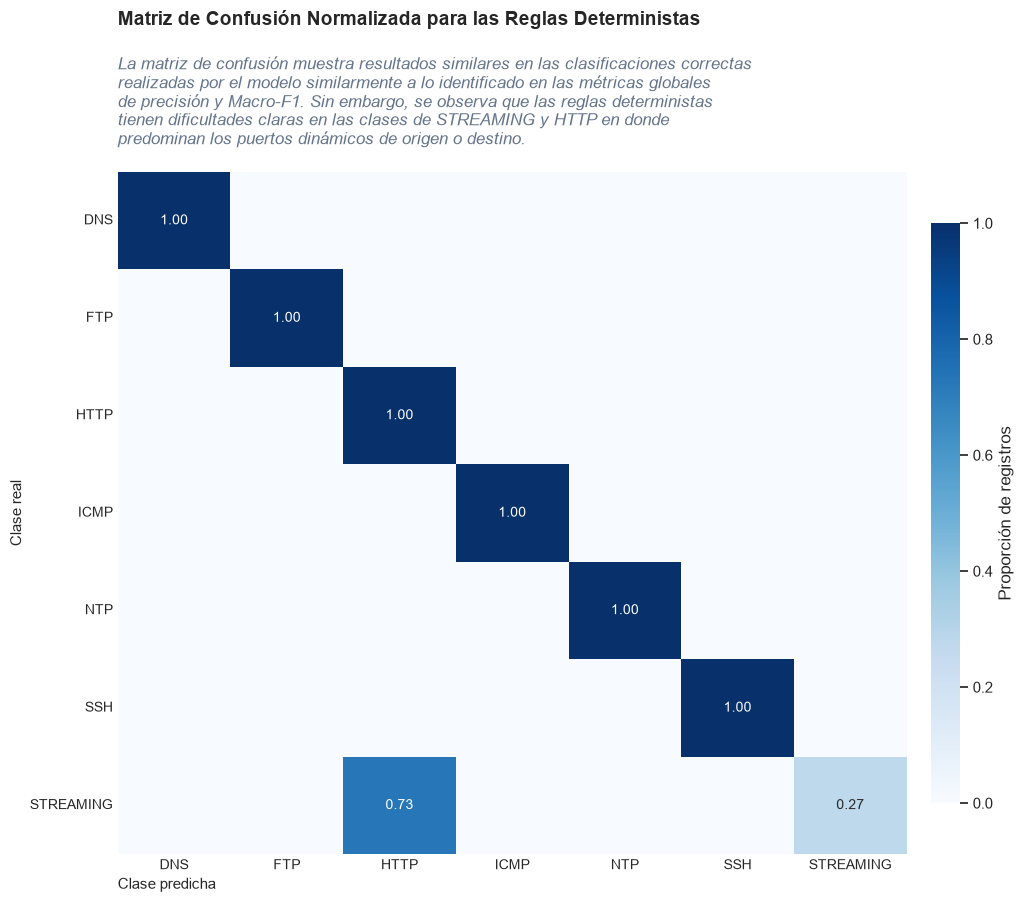

In [38]:
annotations = cm_reglas_normalizada.map(lambda value: f'{value:.2f}' if value >= 0.005 else '')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_reglas_normalizada, annot=annotations, fmt='', cmap='Blues', vmin=0,
    vmax=1, linewidths=0,
    annot_kws={'fontsize': 10},
    cbar_kws={'label': 'Proporción de registros',
               'shrink': 0.85, 'pad': 0.025}, ax=ax,
)
clean_axes(ax)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)
ax.set_xlabel('Clase predicha', fontsize=11, ha='left', x=0)
ax.set_ylabel('Clase real', fontsize=11)
styled_heading(fig, ax, 'Matriz de Confusión Normalizada para las Reglas Deterministas',
               'La matriz de confusión muestra resultados similares en las clasificaciones correctas\n'
               'realizadas por el modelo similarmente a lo identificado en las métricas globales\n'
               'de precisión y Macro-F1. Sin embargo, se observa que las reglas deterministas\n'
               'tienen dificultades claras en las clases de STREAMING y HTTP en donde\n'
               'predominan los puertos dinámicos de origen o destino.')
finalize_figure(fig, '03_matriz_reglas_normalizada')

## 6. Tiempo de inferencia

### 6.1. Muestra y predictor XGBoost por paquete

In [39]:
# Misma muestra, orden y número de repeticiones. Se incluye DMatrix y el empaquetado de reglas.
# El lote XGBoost se informa aparte: su tiempo no equivale a la latencia de un paquete.
sample = X_test[:min(TIMING_SAMPLE_SIZE, len(X_test))]
def xgb_one_by_one(matrix):
    return np.fromiter((int(np.argmax(booster.predict(xgb.DMatrix(row.reshape(1, -1)))[0]))
                        for row in matrix), dtype=np.int64, count=len(matrix))

### 6.2. Comprobación de predicciones

In [40]:
assert np.array_equal(xgb_one_by_one(sample), y_xgb[:len(sample)])
assert np.array_equal(predict_baseline(sample), y_rules[:len(sample)])

### 6.3. Medición de tiempos

In [41]:
timings = []
for method, fn in [('Modelo XGBoost Entrenado, paquete', xgb_one_by_one), ('Reglas, paquete', predict_baseline),
                   ('Modelo XGBoost Entrenado, lote', predict_xgboost)]:
    fn(sample[:min(10, len(sample))])  # calentamiento
    durations = []
    for _ in range(TIMING_REPEATS):
        start = time.perf_counter()
        fn(sample)
        durations.append(time.perf_counter() - start)
    timings.append({'método': method, 'filas': len(sample), 'repeticiones': TIMING_REPEATS,
                    'mediana_ms': float(np.median(durations) * 1000),
                    'mediana_us_por_fila': float(np.median(durations) * 1e6 / len(sample))})

### 6.4. Tabla de tiempos de inferencia

In [42]:
timing_table = pd.DataFrame(timings)
export_table(timing_table, '04_tiempos_inferencia')

In [43]:
timing_table

,método,filas,repeticiones,mediana_ms,mediana_us_por_fila
0,"Modelo XGBoost Entrenado, paquete",1000,3,429.527750,429.527750
1,"Reglas, paquete",1000,3,0.638584,0.638584
2,"Modelo XGBoost Entrenado, lote",1000,3,1.245291,1.245291


### 6.5. Gráfico de latencia por paquete

/var/folders/3c/vp72r8cx1kx1z2gvmfkybjqc0000gn/T/ipykernel_12503/2490323352.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=10)


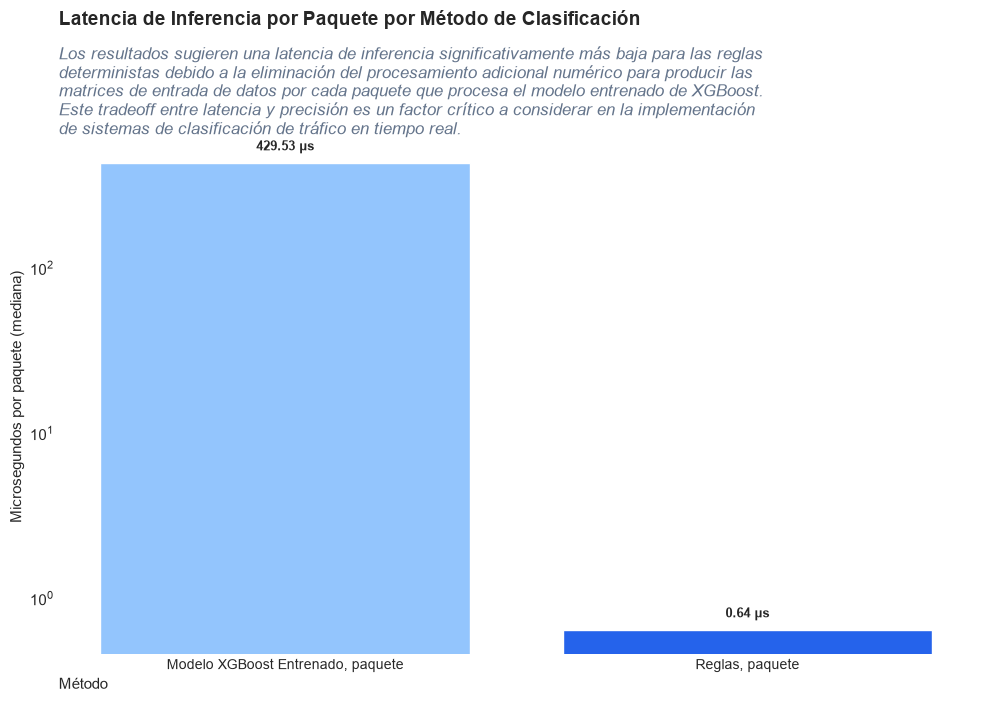

In [44]:
fig, ax = plt.subplots(figsize=(10, 7))
bar_data = timing_table.iloc[:2]
bars = ax.bar(
    bar_data['método'],
    bar_data['mediana_us_por_fila'],
    color=[
        METHOD_COLORS['Modelo XGBoost Entrenado']
        if method.startswith('Modelo XGBoost Entrenado')
        else METHOD_COLORS['Reglas deterministas']
        for method in bar_data['método']
    ]
)

for bar in bars:
    value = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value * 1.15,  # slightly above the bar (works nicely on log scale)
        f'{value:.2f} μs',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )
ax.set_ylabel('Microsegundos por paquete (mediana)', fontsize=11)
ax.set_xlabel('Método', fontsize=11, ha='left', x=0)
ax.set_yscale('log')
clean_axes(ax)
styled_heading(fig, ax, 'Latencia de Inferencia por Paquete por Método de Clasificación',
               'Los resultados sugieren una latencia de inferencia significativamente más baja para las reglas\n'
               'deterministas debido a la eliminación del procesamiento adicional numérico para producir las\n'
               'matrices de entrada de datos por cada paquete que procesa el modelo entrenado de XGBoost.\n'
               'Este tradeoff entre latencia y precisión es un factor crítico a considerar en la implementación\n'
               'de sistemas de clasificación de tráfico en tiempo real.')
finalize_figure(fig, '04_tiempo_por_paquete')

## 7. Solapamiento y combinaciones ambiguas

In [45]:
# Una combinación es la tupla exacta de las cuatro features; no se usan las etiquetas para definir grupos.
train_features = df.iloc[train_idx][feature_columns]
test_features = df.iloc[test_idx][feature_columns]
train_keys = pd.MultiIndex.from_frame(train_features)
test_keys = pd.MultiIndex.from_frame(test_features)
train_unique = train_keys.unique()
test_unique = test_keys.unique()
shared_test_rows = test_keys.isin(train_unique)
shared_unique = test_unique.intersection(train_unique)
overlap = pd.DataFrame([{
    'filas_prueba': len(test_idx), 'filas_prueba_compartidas': int(shared_test_rows.sum()),
    'porcentaje_filas_prueba_compartidas': 100 * shared_test_rows.mean(),
    'combinaciones_entrenamiento': len(train_unique), 'combinaciones_prueba': len(test_unique),
    'combinaciones_compartidas': len(shared_unique),
    'porcentaje_combinaciones_prueba_compartidas': 100 * len(shared_unique) / len(test_unique)
}])
display(overlap)
export_table(overlap, '05_solapamiento')

combination_classes = (df.groupby(feature_columns, dropna=False, observed=True)[target_column]
                       .agg(observaciones='size', clases_distintas='nunique',
                            clases=lambda values: ', '.join(sorted(values.unique()))).reset_index())
ambiguous = combination_classes.loc[combination_classes['clases_distintas'] > 1]
ambiguous = ambiguous.sort_values(['observaciones', 'clases_distintas'], ascending=False)
print(f'Combinaciones con más de una clase: {len(ambiguous):,}; observaciones afectadas: {int(ambiguous.observaciones.sum()):,}')
display(ambiguous.head(30))
export_table(ambiguous, '06_combinaciones_ambiguas')

test_segments = []
segment_support_rows = []
for segment, mask in [('vista_en_entrenamiento', shared_test_rows), ('nueva', ~shared_test_rows)]:
    for class_id, name in enumerate(classes):
        segment_support_rows.append({'segmento': segment, 'clase': name,
                                     'soporte': int(np.count_nonzero(y_test[mask] == class_id))})
for method, predicted in predictions.items():
    for segment, mask in [('vista_en_entrenamiento', shared_test_rows), ('nueva', ~shared_test_rows)]:
        if mask.sum():
            test_segments.append({'método': method, 'segmento': segment, 'filas': int(mask.sum()),
                                  'accuracy': accuracy_score(y_test[mask], predicted[mask]),
                                  'macro_f1_7_clases': f1_score(y_test[mask], predicted[mask],
                                                               labels=class_ids, average='macro', zero_division=0)})
segment_table = pd.DataFrame(test_segments)
segment_support = pd.DataFrame(segment_support_rows)
display(segment_table, segment_support)
export_table(segment_table, '07_metricas_combinaciones_vistas_y_nuevas')
export_table(segment_support, '08_soporte_combinaciones_vistas_y_nuevas')
print('La evaluación en combinaciones nuevas es un análisis de sensibilidad del modelo guardado;')
print('no equivale a entrenar y evaluar con una partición por grupos.')


,filas_prueba,filas_prueba_compartidas,porcentaje_filas_prueba_compartidas,combinaciones_entrenamiento,combinaciones_prueba,combinaciones_compartidas,porcentaje_combinaciones_prueba_compartidas
0,66470,55090,82.879495,55553,35475,25708,72.467935


Combinaciones con más de una clase: 0; observaciones afectadas: 0


,eth_type,ip_proto,src_port,dst_port,observaciones,clases_distintas,clases


,método,segmento,filas,accuracy,macro_f1_7_clases
0,Modelo XGBoost Entrenado,vista_en_entrenamiento,55090,0.999982,0.856913
1,Modelo XGBoost Entrenado,nueva,11380,0.998067,0.593264
2,Reglas deterministas,vista_en_entrenamiento,55090,0.995117,0.750865
3,Reglas deterministas,nueva,11380,0.988049,0.550067


,segmento,clase,soporte
0,vista_en_entrenamiento,DNS,8070
1,vista_en_entrenamiento,FTP,18
2,vista_en_entrenamiento,HTTP,46257
3,vista_en_entrenamiento,ICMP,92
4,vista_en_entrenamiento,NTP,0
5,vista_en_entrenamiento,SSH,340
6,vista_en_entrenamiento,STREAMING,313
7,nueva,DNS,7995
8,nueva,FTP,9
9,nueva,HTTP,3236


La evaluación en combinaciones nuevas es un análisis de sensibilidad del modelo guardado;
no equivale a entrenar y evaluar con una partición por grupos.


In [47]:
segment_table

,método,segmento,filas,accuracy,macro_f1_7_clases
0,Modelo XGBoost Entrenado,vista_en_entrenamiento,55090,0.999982,0.856913
1,Modelo XGBoost Entrenado,nueva,11380,0.998067,0.593264
2,Reglas deterministas,vista_en_entrenamiento,55090,0.995117,0.750865
3,Reglas deterministas,nueva,11380,0.988049,0.550067


In [48]:
train_keys

MultiIndex([(2048,  6, 43162,   443),
            (2048, 17, 51421,    53),
            (2048, 17,    53, 40408),
            (2048,  6,   443, 49608),
            (2048,  6,   443, 52766),
            (2048,  6, 38504,   443),
            (2048, 17,    53, 57849),
            (2048, 17, 48708,    53),
            (2048,  6,   443, 49690),
            (2048,  6,   443, 44868),
            ...
            (2048, 17,    53, 46244),
            (2048,  6, 55478,   443),
            (2048,  6, 34404,   443),
            (2048, 17,    53, 48543),
            (2048,  6, 40984,   443),
            (2048, 17,    53, 43149),
            (2048,  6, 41654,   443),
            (2048, 17, 59986,    53),
            (2048, 17, 38472,    53),
            (2048,  6, 41096,   443)],
           names=['eth_type', 'ip_proto', 'src_port', 'dst_port'], length=155094)

In [49]:
segment_support

,segmento,clase,soporte
0,vista_en_entrenamiento,DNS,8070
1,vista_en_entrenamiento,FTP,18
2,vista_en_entrenamiento,HTTP,46257
3,vista_en_entrenamiento,ICMP,92
4,vista_en_entrenamiento,NTP,0
5,vista_en_entrenamiento,SSH,340
6,vista_en_entrenamiento,STREAMING,313
7,nueva,DNS,7995
8,nueva,FTP,9
9,nueva,HTTP,3236


In [53]:
from sklearn.metrics import precision_recall_fscore_support

diagnostic_rows = []

segments = {
    "vista_en_entrenamiento": shared_test_rows,
    "nueva": ~shared_test_rows
}

for method, predicted in predictions.items():
    for segment, mask in segments.items():

        precision, recall, f1, support = (
            precision_recall_fscore_support(
                y_test[mask],
                predicted[mask],
                labels=class_ids,
                zero_division=0
            )
        )

        for i, class_name in enumerate(classes):
            diagnostic_rows.append({
                "metodo": method,
                "segmento": segment,
                "clase": class_name,
                "soporte": int(support[i]),
                "precision": float(precision[i]),
                "recall": float(recall[i]),
                "f1": float(f1[i])
            })

diagnostic_table = pd.DataFrame(diagnostic_rows)


diagnostic_table.sort_values(
        ["metodo", "clase", "segmento"]
    )


,metodo,segmento,clase,soporte,precision,recall,f1
7,Modelo XGBoost Entrenado,nueva,DNS,7995,1.000000,1.000000,1.000000
0,Modelo XGBoost Entrenado,vista_en_entrenamiento,DNS,8070,1.000000,1.000000,1.000000
8,Modelo XGBoost Entrenado,nueva,FTP,9,1.000000,1.000000,1.000000
1,Modelo XGBoost Entrenado,vista_en_entrenamiento,FTP,18,1.000000,1.000000,1.000000
9,Modelo XGBoost Entrenado,nueva,HTTP,3236,0.998449,0.994747,0.996594
2,Modelo XGBoost Entrenado,vista_en_entrenamiento,HTTP,46257,1.000000,0.999978,0.999989
10,Modelo XGBoost Entrenado,nueva,ICMP,0,0.000000,0.000000,0.000000
3,Modelo XGBoost Entrenado,vista_en_entrenamiento,ICMP,92,1.000000,1.000000,1.000000
11,Modelo XGBoost Entrenado,nueva,NTP,7,0.111111,0.285714,0.160000
4,Modelo XGBoost Entrenado,vista_en_entrenamiento,NTP,0,0.000000,0.000000,0.000000


In [55]:
diagnostic_table

,metodo,segmento,clase,soporte,precision,recall,f1
0,Modelo XGBoost Entrenado,vista_en_entrenamiento,DNS,8070,1.000000,1.000000,1.000000
1,Modelo XGBoost Entrenado,vista_en_entrenamiento,FTP,18,1.000000,1.000000,1.000000
2,Modelo XGBoost Entrenado,vista_en_entrenamiento,HTTP,46257,1.000000,0.999978,0.999989
3,Modelo XGBoost Entrenado,vista_en_entrenamiento,ICMP,92,1.000000,1.000000,1.000000
4,Modelo XGBoost Entrenado,vista_en_entrenamiento,NTP,0,0.000000,0.000000,0.000000
5,Modelo XGBoost Entrenado,vista_en_entrenamiento,SSH,340,1.000000,1.000000,1.000000
6,Modelo XGBoost Entrenado,vista_en_entrenamiento,STREAMING,313,0.996815,1.000000,0.998405
7,Modelo XGBoost Entrenado,nueva,DNS,7995,1.000000,1.000000,1.000000
8,Modelo XGBoost Entrenado,nueva,FTP,9,1.000000,1.000000,1.000000
9,Modelo XGBoost Entrenado,nueva,HTTP,3236,0.998449,0.994747,0.996594
